# Quantum Entanglement and the Bell Inequality — an Experiment You Can Run

A complete, from-scratch simulation of a **CHSH Bell test**: prepare entangled pairs,
choose measurement settings, sample finite-shot outcomes, compute the correlation
function, and watch the local-realist bound break — then add the noise a real device has
and find exactly where the violation dies.

| Part | Topic | What you get |
|---|---|---|
| 1 | Bell states | all four, built by circuit, with a Bell-basis analyser |
| 2 | Correlation `E(a,b)` | joint probabilities from projectors, exact and sampled |
| 3 | CHSH inequality | local-realist bound 2, quantum `2√2`, Tsirelson limit by brute-force scan |
| 4 | The experiment | finite shots, coincidence counts, `S ± σ`, 400 repeated runs |
| 5 | CHSH game | the same inequality as a game: classical 75% vs quantum 85.4% |
| 6 | Noise | depolarising, dephasing, bit-flip, measurement error — thresholds and a device budget |
| 7 | Self-tests | 90+ assertions |
| 8 | Qiskit cross-check | same correlations and the same noisy channels, computed by Qiskit |

**Run it in Google Colab:** `File > Open notebook > Upload`, then `Runtime > Run all`.
Parts 1–7 need only NumPy and Matplotlib (already in Colab). Part 8 installs Qiskit itself
and is optional.

**The physics in one paragraph.** Two observers, Alice and Bob, share a pair of qubits.
Each freely chooses one of two measurement settings, `a` or `a′` for Alice, `b` or `b′`
for Bob, and each gets a result `±1`. If the results were written down in advance by some
shared hidden instruction list — *local realism* — then the CHSH combination

$$S = \big|E(a,b) + E(a,b') + E(a',b) - E(a',b')\big| \;\le\; 2$$

cannot exceed 2. Entangled qubits reach `2√2 ≈ 2.828`, the **Tsirelson bound**, and no
physical theory reaches 4. That gap is what Bell tests measure, and it is what this
notebook simulates, samples and then degrades with noise.

(Throughout, the CHSH combination is written `S = |E(a,b) + E(a,b′) + E(a′,b) − E(a′,b′)|`
with settings `a = 0`, `a′ = π/2`, `b = π/4`, `b′ = −π/4`. Which of the four terms carries
the minus sign is pure bookkeeping — relabelling `b′ → −b′` moves it anywhere you like, and
the bound, the quantum value and the game win rate are all unchanged.)


## Part 0 · The three ingredients

1. **Observable.** A measurement with outcomes `±1` is a Hermitian matrix `M` with
   eigenvalues `±1`. Measuring a qubit "at angle θ" in the x–z plane means
   `M(θ) = cos θ · Z + sin θ · X`.
2. **Projector.** The probability of outcome `α ∈ {+1, −1}` is
   `P(α) = Tr[Π(α) ρ]` with `Π(α) = (I + α·M)/2`. Two projectors, one per lab, give the
   **coincidence (joint) probabilities** `P(α,β) = Tr[(Π_a(α) ⊗ Π_b(β)) ρ]`.
3. **Correlation.** `E(a,b) = Σ_{α,β} αβ · P(α,β)`, which equals
   `Tr[(M(a) ⊗ M(b)) ρ]`. Perfectly correlated → `+1`, anti-correlated → `−1`,
   independent → `0`.

Everything else in this notebook is those three lines applied to entangled states, plus
counting finite samples honestly.


In [1]:
import math

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
H = (1 / math.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)

rng = np.random.default_rng(42)

print("Pauli squares:", np.allclose(X @ X, I2), np.allclose(Y @ Y, I2), np.allclose(Z @ Z, I2))
print("X and Z anticommute:", np.allclose(X @ Z + Z @ X, 0))
print("H Z H = X:", np.allclose(H @ Z @ H, X))

# A measurement at angle theta, and its two projectors.
def observable(theta: float) -> np.ndarray:
    return math.cos(theta) * Z + math.sin(theta) * X


def projector(theta: float, alpha: int) -> np.ndarray:
    return 0.5 * (I2 + alpha * observable(theta))


for theta in (0.0, math.pi / 4, math.pi / 2):
    P_plus, P_minus = projector(theta, +1), projector(theta, -1)
    print(f"theta={theta:.3f}: P(+)+P(-) = I -> {np.allclose(P_plus + P_minus, I2)}, "
          f"orthogonal projectors -> {np.allclose(P_plus @ P_minus, 0)}, "
          f"trace 1 -> {P_plus.trace().real:.3f} each")

Pauli squares: True True True
X and Z anticommute: True
H Z H = X: True
theta=0.000: P(+)+P(-) = I -> True, orthogonal projectors -> True, trace 1 -> 1.000 each
theta=0.785: P(+)+P(-) = I -> True, orthogonal projectors -> True, trace 1 -> 1.000 each
theta=1.571: P(+)+P(-) = I -> True, orthogonal projectors -> True, trace 1 -> 1.000 each


---
## Part 1 · Creating the Bell states

The simulator core is the same one built step-by-step in the first project
(*Quantum_Circuit.ipynb*), condensed here so this notebook is self-contained:
a state vector of `2ⁿ` complex amplitudes, gates applied by tensor contraction, and a
density matrix when noise enters. Convention: **qubit 0 is the leftmost bit** of a ket.

The four **maximally entangled Bell states** come from one circuit plus Pauli corrections:

| State | Circuit | Vector |
|---|---|---|
| `\|Φ⁺⟩` | `H(q0) · CNOT(q0→q1)` | `(|00⟩ + \|11⟩)/√2` |
| `\|Φ⁻⟩` | add `Z(q0)` | `(|00⟩ − \|11⟩)/√2` |
| `\|Ψ⁺⟩` | add `X(q1)` | `(|01⟩ + \|10⟩)/√2` |
| `\|Ψ⁻⟩` | add `X(q0)` then `Z(q0)` | `(|01⟩ − \|10⟩)/√2` |

Each qubit *alone* is maximally mixed — `ρ_A = ρ_B = I/2` — yet the pair is in a pure
state. That combination is the whole phenomenon, and it is what makes the marginals
indistinguishable from a classical coin while the correlations are not.


In [2]:
def zero_state(n: int) -> np.ndarray:
    psi = np.zeros(2**n, dtype=complex)
    psi[0] = 1.0
    return psi


def apply_unitary(psi: np.ndarray, U: np.ndarray, targets: list, n: int) -> np.ndarray:
    """Apply U to the listed qubits (targets[0] = U's most significant index)."""
    k = len(targets)
    tensor = np.asarray(psi, dtype=complex).reshape([2] * n)
    tensor = np.moveaxis(tensor, targets, list(range(k)))
    tensor = (U @ tensor.reshape(2**k, -1)).reshape([2] * k + [2] * (n - k))
    return np.moveaxis(tensor, list(range(k)), targets).reshape(2**n)


class Circuit:
    def __init__(self, n: int, name: str = "circuit"):
        self.n, self.name = n, name
        self.state = zero_state(n)
        self.ops = []

    def gate(self, U, q, glyph):
        self.state = apply_unitary(self.state, U, [q], self.n)
        self.ops.append((glyph, [q]))
        return self

    def h(self, q):
        return self.gate(H, q, "H")

    def x(self, q):
        return self.gate(X, q, "X")

    def z(self, q):
        return self.gate(Z, q, "Z")

    def cnot(self, control, target):
        cx = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)
        self.state = apply_unitary(self.state, cx, [control, target], self.n)
        self.ops.append(("CNOT", [control, target]))
        return self

    def draw(self) -> str:
        cols = [[] for _ in range(self.n)]
        for glyph, qubits in self.ops:
            if glyph == "CNOT":
                boxes, lo, hi = {qubits[0]: "o", qubits[1]: "+"}, min(qubits), max(qubits)
            else:
                boxes, lo, hi = {q: glyph for q in qubits}, min(qubits), max(qubits)
            width = max(len(v) for v in boxes.values()) + 2
            for q in range(self.n):
                if q in boxes:
                    cols[q].append(boxes[q].center(width))
                elif lo < q < hi:
                    cols[q].append("|".center(width))
                else:
                    cols[q].append("-" * width)
        return "\n".join(f"q{q}: |0> -" + "-".join(cols[q]) + "-" for q in range(self.n))


def density_matrix(psi: np.ndarray) -> np.ndarray:
    return np.outer(psi, np.conjugate(psi))


def partial_trace(rho: np.ndarray, keep: list, n: int) -> np.ndarray:
    keep = sorted(keep)
    rows, cols = "abcd", "efgh"
    ins = [rows[q] for q in range(n)] + [cols[q] if q in keep else rows[q] for q in range(n)]
    out = "".join(rows[q] for q in keep) + "".join(cols[q] for q in keep)
    return np.einsum("".join(ins) + "->" + out, rho.reshape([2] * (2 * n))).reshape(2 ** len(keep), 2 ** len(keep))


def bell_circuit(name: str) -> Circuit:
    circ = Circuit(2, f"Bell {name}").h(0).cnot(0, 1)
    if name == "Phi-":
        circ.z(0)
    elif name == "Psi+":
        circ.x(1)
    elif name == "Psi-":
        circ.x(0).z(0)
    return circ


BELL = {name: bell_circuit(name).state for name in ("Phi+", "Phi-", "Psi+", "Psi-")}

print(bell_circuit("Phi+").draw())
print()
for name, psi in BELL.items():
    rho = density_matrix(psi)
    marg = partial_trace(rho, [0], 2)
    print(f"|{name}>  amplitudes {np.round(psi, 3)}")
    print(f"        normalised: {np.isclose(np.linalg.norm(psi), 1)}   "
          f"reduced state = I/2: {np.allclose(marg, I2 / 2)}   "
          f"purity of pair: {np.trace(rho @ rho).real:.3f}, of one qubit: {np.trace(marg @ marg).real:.3f}")

print("\nthe four Bell states are orthonormal:",
      all(np.allclose(np.vdot(BELL[a], BELL[b]), 1.0 if a == b else 0.0)
          for a in BELL for b in BELL))

q0: |0> - H - o -
q1: |0> ----- + -

|Phi+>  amplitudes [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]
        normalised: True   reduced state = I/2: True   purity of pair: 1.000, of one qubit: 0.500
|Phi->  amplitudes [ 0.707+0.j  0.   +0.j  0.   +0.j -0.707+0.j]
        normalised: True   reduced state = I/2: True   purity of pair: 1.000, of one qubit: 0.500
|Psi+>  amplitudes [0.   +0.j 0.707+0.j 0.707+0.j 0.   +0.j]
        normalised: True   reduced state = I/2: True   purity of pair: 1.000, of one qubit: 0.500
|Psi->  amplitudes [ 0.   +0.j  0.707+0.j -0.707+0.j  0.   +0.j]
        normalised: True   reduced state = I/2: True   purity of pair: 1.000, of one qubit: 0.500

the four Bell states are orthonormal: True


prepared   analyser outcome    identified   probabilities
|Phi+><Phi+                 00   |       Phi+>   [1. 0. 0. 0.]
|Phi-><Phi-                 10   |       Phi->   [0. 0. 1. 0.]
|Psi+><Psi+                 01   |       Psi+>   [0. 1. 0. 0.]
|Psi-><Psi-                 11   |       Psi->   [0. 0. 0. 1.]

perfect discrimination: the four Bell states are an orthonormal basis, so a
circuit made of one CNOT and one Hadamard reads out which one you have.


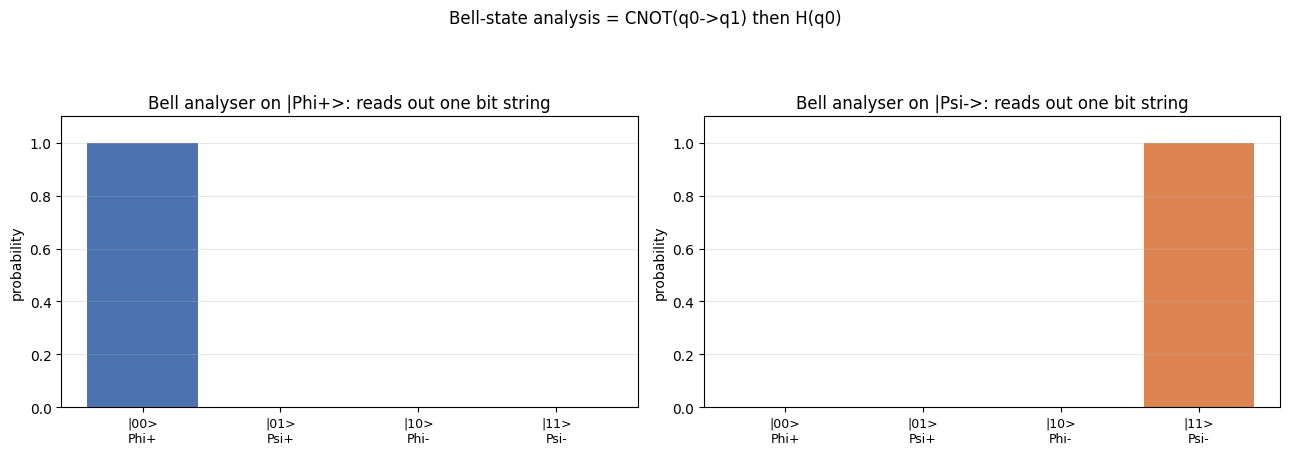

In [3]:
# A Bell-basis analyser: CNOT then H maps each Bell state onto a distinct bit string.
def bell_analyser(state: np.ndarray) -> np.ndarray:
    psi = apply_unitary(state, np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex), [0, 1], 2)
    return apply_unitary(psi, H, [0], 2)


MAP = {"00": "Phi+", "10": "Phi-", "01": "Psi+", "11": "Psi-"}
print(f"{'prepared':<9} {'analyser outcome':>17}   {'identified':>11}   probabilities")
for name, psi in BELL.items():
    p = np.abs(bell_analyser(psi)) ** 2
    winner = MAP[format(int(np.argmax(p)), "02b")]
    print(f"|{name}><{name:<5} {format(int(np.argmax(p)), '02b'):>17}   |{winner:>11}>   {np.round(p, 3)}")
print("\nperfect discrimination: the four Bell states are an orthonormal basis, so a")
print("circuit made of one CNOT and one Hadamard reads out which one you have.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
labels = ["|00>\nPhi+", "|01>\nPsi+", "|10>\nPhi-", "|11>\nPsi-"]
for ax, (name, psi) in zip(axes, [("Phi+", BELL["Phi+"]), ("Psi-", BELL["Psi-"])]):
    p = np.abs(bell_analyser(psi)) ** 2
    ax.bar(range(4), p, color=["#4c72b0", "#55a868", "#c44e52", "#dd8452"])
    ax.set_xticks(range(4), labels, fontsize=9)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel("probability")
    ax.set_title(f"Bell analyser on |{name}>: reads out one bit string")
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Bell-state analysis = CNOT(q0->q1) then H(q0)")
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

---
## Part 2 · The correlation function `E(a,b)`

Alice measures at angle `a`, Bob at `b`. The four coincidence probabilities come from the
joint projectors, and `E = P(+,+) + P(−,−) − P(+,−) − P(−,+)`.

For the Bell states, doing the algebra by hand gives

$$|\Phi^{\pm}\rangle:\; E(a,b) = \cos(a \mp b), \qquad |\Psi^{\pm}\rangle:\; E(a,b) = -\cos(a \pm b)$$

so `Φ⁺` correlates whenever the two analysers point the **same** way, and the singlet
`Ψ⁻` anti-correlates whenever they do. We compute it numerically from the density matrix —
no hand-derived formula is trusted until it matches the simulation.

Only the `x–z` plane is needed: the `y` component would let us build the same correlations
with different angles, but the standard CHSH settings all live in one plane.


state     exact E(a,b)   cos(a-b)   cos(a+b)   -cos(a-b)   -cos(a+b)
|Phi+><Phi+      0.724836   0.724836   <- matches
|Phi-><Phi-      0.189641   0.189641   <- matches
|Psi+><Psi+     -0.189641  -0.189641   <- matches
|Psi-><Psi-     -0.724836  -0.724836   <- matches

coincidence probabilities, |Phi+>, same settings a=b=0:
  P(+,+)=0.5  P(+,-)=0   P(-,+)=0   P(-,-)=0.5  -> always agree
   [0.5 0.  0.  0.5]
orthogonal settings a=0, b=pi/2:
   [0.25 0.25 0.25 0.25] -> 50/50 everywhere, E=0


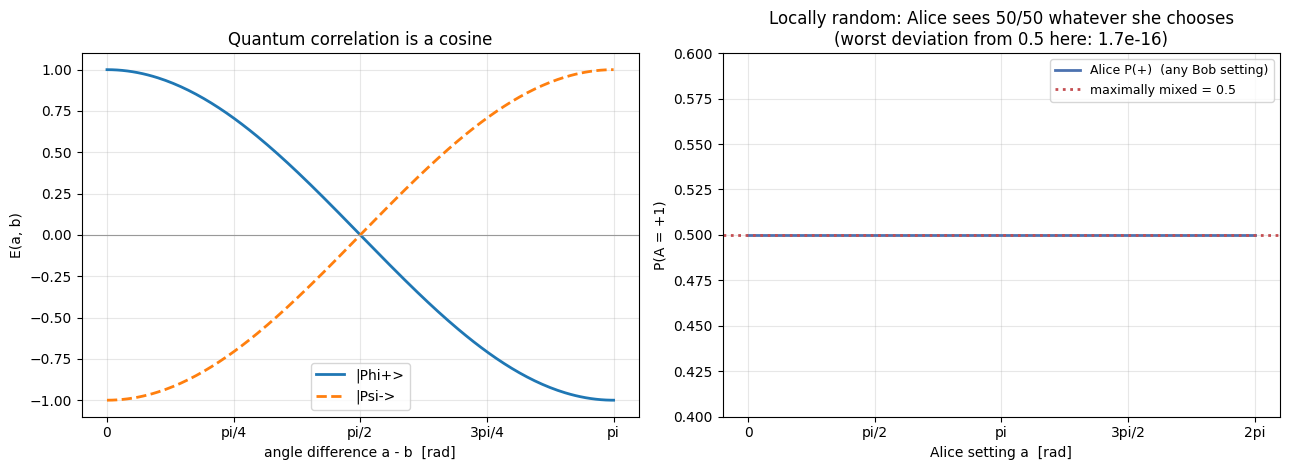

In [4]:
def joint_probabilities(rho: np.ndarray, a: float, b: float) -> np.ndarray:
    """[P(+,+), P(+,-), P(-,+), P(-,-)] for measurements at a (Alice) and b (Bob)."""
    out = np.empty(4)
    for i, alpha in enumerate((+1, -1)):
        for j, beta in enumerate((+1, -1)):
            op = np.kron(projector(a, alpha), projector(b, beta))
            out[2 * i + j] = np.real(np.trace(rho @ op))
    return out


def correlation(rho: np.ndarray, a: float, b: float) -> float:
    """E(a,b) = Tr[(M(a) tensor M(b)) rho] -- computed two ways and cross-checked."""
    direct = float(np.real(np.trace(rho @ np.kron(observable(a), observable(b)))))
    p = joint_probabilities(rho, a, b)
    from_counts = float(p[0] - p[1] - p[2] + p[3])
    assert abs(direct - from_counts) < 1e-12, "the two routes must agree"
    return direct


print(f"{'state':<8} {'exact E(a,b)':>13}  {'cos(a-b)':>9}  {'cos(a+b)':>9}  {'-cos(a-b)':>10}  {'-cos(a+b)':>10}")
a_test, b_test = 0.31, 1.07
for name, psi in BELL.items():
    e = correlation(density_matrix(psi), a_test, b_test)
    preds = {"Phi+": math.cos(a_test - b_test), "Phi-": math.cos(a_test + b_test),
             "Psi+": -math.cos(a_test + b_test), "Psi-": -math.cos(a_test - b_test)}
    print(f"|{name}><{name:<4} {e:>13.6f}  {preds[name]:>9.6f}",
          "  <- matches" if abs(e - preds[name]) < 1e-12 else "")

print("\ncoincidence probabilities, |Phi+>, same settings a=b=0:")
print("  P(+,+)=0.5  P(+,-)=0   P(-,+)=0   P(-,-)=0.5  -> always agree")
print("  ", np.round(joint_probabilities(density_matrix(BELL['Phi+']), 0.0, 0.0), 6))
print("orthogonal settings a=0, b=pi/2:")
print("  ", np.round(joint_probabilities(density_matrix(BELL['Phi+']), 0.0, math.pi / 2), 6), "-> 50/50 everywhere, E=0")

# The correlation curve, and the marginals that make each side look random.
deltas = np.linspace(0, math.pi, 200)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name, style in [("Phi+", "-"), ("Psi-", "--")]:
    rho = density_matrix(BELL[name])
    axes[0].plot(deltas, [correlation(rho, d, 0.0) for d in deltas], style, lw=2, label=f"|{name}>")
axes[0].axhline(0, color="0.6", lw=0.8)
axes[0].set_xlabel("angle difference a - b  [rad]")
axes[0].set_ylabel("E(a, b)")
axes[0].set_title("Quantum correlation is a cosine")
axes[0].set_xticks([0, math.pi / 4, math.pi / 2, 3 * math.pi / 4, math.pi],
                   ["0", "pi/4", "pi/2", "3pi/4", "pi"])
axes[0].legend()
axes[0].grid(alpha=0.3)

phis = np.linspace(0, 2 * math.pi, 200)
rho = density_matrix(BELL["Phi+"])
pp = [joint_probabilities(rho, p, 0.0)[0] + joint_probabilities(rho, p, 0.0)[2] for p in phis]
axes[1].plot(phis, pp, color="#4c72b0", lw=2, label="Alice P(+)  (any Bob setting)")
axes[1].axhline(0.5, color="#c44e52", ls=":", lw=2, label="maximally mixed = 0.5")
axes[1].set_xlabel("Alice setting a  [rad]")
axes[1].set_ylabel("P(A = +1)")
axes[1].set_ylim(0.4, 0.6)
axes[1].set_title(f"Locally random: Alice sees 50/50 whatever she chooses\n"
                  f"(worst deviation from 0.5 here: {max(abs(np.array(pp) - 0.5)):.1e})")
axes[1].set_xticks([0, math.pi / 2, math.pi, 3 * math.pi / 2, 2 * math.pi], ["0", "pi/2", "pi", "3pi/2", "2pi"])
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

---
## Part 3 · The CHSH inequality

Pick the combination

$$S = \big|E(a,b) + E(a,b') + E(a',b) - E(a',b')\big|$$

* **Local realism (Bell 1964, CHSH 1969):** if each pair carries a pre-agreed instruction
  list, `S ≤ 2`. This is a theorem about *any* such model, not about a particular one.
* **Quantum mechanics:** `S = 2√2 ≈ 2.828` (Tsirelson's bound) with
  `a = 0`, `a′ = π/2`, `b = π/4`, `b′ = −π/4` on `|Φ⁺⟩`.
* **Algebraic maximum:** `S = 4`, unreachable by any no-signalling theory that is also
  a probability theory.

To show the bound is not a quirk of one angle choice, we scan the whole four-dimensional
angle space for both the quantum and a concrete hidden-variable model and compare the
maxima found. The classical model is the standard one: each pair carries a shared angle
`λ`, and each lab answers `+1` when its analyser is closer to `λ` than perpendicular — a
deterministic, local rule that reproduces the 50/50 marginals exactly.


standard CHSH settings: a=0, a'=pi/2, b=pi/4, b'=-pi/4
  E(a,b)     = +0.707107
  E(a,b')    = +0.707107
  E(a',b)    = +0.707107
  E(a',b')   = -0.707107
  S = |+0.707 + (+0.707) + (+0.707) - (-0.707)| = 2.828427
  2*sqrt(2) = 2.828427   local-realist bound = 2   violation by 0.8284

same settings on the classical model: S = 2.000000  (saturates 2, never exceeds it)

grid scan over 65,536 angle quadruples (|Phi+>, E = cos(a-b)):
  quantum max    = 2.8284   (Tsirelson 2*sqrt(2) = 2.8284)
  classical max  = 2.0000   (CHSH bound = 2)
  best angles found (a, a', b, b') in units of pi: [0.0, 0.5, 1.25, 0.75]


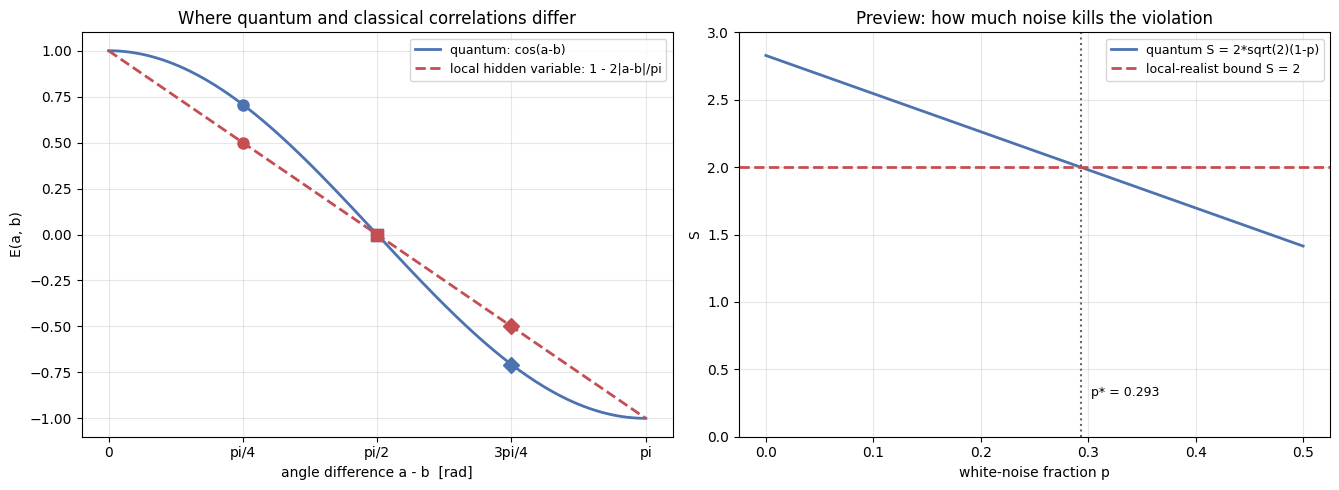

In [5]:
def chsh(rho: np.ndarray, a: float, ap: float, b: float, bp: float) -> tuple:
    e_ab, e_abp = correlation(rho, a, b), correlation(rho, a, bp)
    e_apb, e_apbp = correlation(rho, ap, b), correlation(rho, ap, bp)
    return abs(e_ab + e_abp + e_apb - e_apbp), (e_ab, e_abp, e_apb, e_apbp)


def classical_correlation(delta):
    """Shared-angle hidden variable: A = sign(cos(a - L)), B = sign(cos(b - L)).

    Averaging over a uniformly distributed L gives E = 1 - 2|a-b|/pi on [0, pi].
    Written with np.where so it works on a single angle or on a whole meshgrid.
    """
    d = np.abs(delta) % (2 * math.pi)
    d = np.where(d > math.pi, 2 * math.pi - d, d)
    return 1.0 - 2.0 * d / math.pi


def classical_chsh(a, ap, b, bp):
    return float(abs(classical_correlation(a - b) + classical_correlation(a - bp)
                     + classical_correlation(ap - b) - classical_correlation(ap - bp)))


# The textbook settings.
A, AP, B, BP = 0.0, math.pi / 2, math.pi / 4, -math.pi / 4
rho_phi_plus = density_matrix(BELL["Phi+"])
S_q, terms = chsh(rho_phi_plus, A, AP, B, BP)
print("standard CHSH settings: a=0, a'=pi/2, b=pi/4, b'=-pi/4")
for label, e in zip(["E(a,b)", "E(a,b')", "E(a',b)", "E(a',b')"], terms):
    print(f"  {label:<10} = {e:+.6f}")
print(f"  S = |{terms[0]:+.3f} + ({terms[1]:+.3f}) + ({terms[2]:+.3f}) - ({terms[3]:+.3f})| = {S_q:.6f}")
print(f"  2*sqrt(2) = {2 * math.sqrt(2):.6f}   local-realist bound = 2   violation by {S_q - 2:.4f}")
assert math.isclose(S_q, 2 * math.sqrt(2), abs_tol=1e-9)

print(f"\nsame settings on the classical model: S = {classical_chsh(A, AP, B, BP):.6f}  (saturates 2, never exceeds it)")

# Brute-force scan of the whole angle space for both theories.
grid = np.arange(16) * (math.pi / 8)          # includes 0, pi/4, pi/2 and -pi/4 (= 7pi/8)
G1, G2, G3, G4 = np.meshgrid(grid, grid, grid, grid, indexing="ij")
quantum_scan = np.abs(np.cos(G1 - G3) + np.cos(G1 - G4) + np.cos(G2 - G3) - np.cos(G2 - G4))
classical_scan = np.abs(classical_correlation(G1 - G3) + classical_correlation(G1 - G4)
                        + classical_correlation(G2 - G3) - classical_correlation(G2 - G4))
print(f"\ngrid scan over {grid.size ** 4:,} angle quadruples (|Phi+>, E = cos(a-b)):")
print(f"  quantum max    = {quantum_scan.max():.4f}   (Tsirelson 2*sqrt(2) = {2 * math.sqrt(2):.4f})")
print(f"  classical max  = {classical_scan.max():.4f}   (CHSH bound = 2)")
best = np.unravel_index(np.argmax(quantum_scan), quantum_scan.shape)
print("  best angles found (a, a', b, b') in units of pi:",
      [round(float(grid[i] / math.pi), 3) for i in best])

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))
delta = np.linspace(0, math.pi, 200)
axes[0].plot(delta, np.cos(delta), lw=2, color="#4c72b0", label="quantum: cos(a-b)")
axes[0].plot(delta, [classical_correlation(d) for d in delta], lw=2, color="#c44e52",
             ls="--", label="local hidden variable: 1 - 2|a-b|/pi")
for d, marker in [(math.pi / 4, "o"), (math.pi / 2, "s"), (3 * math.pi / 4, "D")]:
    axes[0].plot(d, math.cos(d), marker, color="#4c72b0", ms=8)
    axes[0].plot(d, classical_correlation(d), marker, color="#c44e52", ms=8)
axes[0].set_xlabel("angle difference a - b  [rad]")
axes[0].set_ylabel("E(a, b)")
axes[0].set_title("Where quantum and classical correlations differ")
axes[0].set_xticks([0, math.pi / 4, math.pi / 2, 3 * math.pi / 4, math.pi],
                   ["0", "pi/4", "pi/2", "3pi/4", "pi"])
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

x = np.linspace(0, 0.5, 120)
axes[1].plot(x, 2 * math.sqrt(2) * (1 - x), lw=2, color="#4c72b0", label="quantum S = 2*sqrt(2)(1-p)")
axes[1].axhline(2, color="#c44e52", ls="--", lw=2, label="local-realist bound S = 2")
axes[1].axvline(1 - 1 / math.sqrt(2), color="0.4", ls=":", lw=1.5)
axes[1].text(1 - 1 / math.sqrt(2) + 0.01, 0.3, f"p* = {1 - 1 / math.sqrt(2):.3f}", fontsize=9)
axes[1].set_xlabel("white-noise fraction p")
axes[1].set_ylabel("S")
axes[1].set_title("Preview: how much noise kills the violation")
axes[1].set_ylim(0, 3)
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [6]:
# Every Bell state violates CHSH - it just needs its own settings, found by search.
E_FORM = {
    "Phi+": lambda a, b: np.cos(a - b),
    "Phi-": lambda a, b: np.cos(a + b),
    "Psi+": lambda a, b: -np.cos(a + b),
    "Psi-": lambda a, b: -np.cos(a - b),
}


def best_settings(name: str, steps: int = 32) -> tuple:
    """Search the angle space for the settings that maximise S for this Bell state."""
    g = np.arange(steps) * (2 * math.pi / steps)
    E = E_FORM[name]
    G1, G2, G3, G4 = np.meshgrid(g, g, g, g, indexing="ij")
    scan = np.abs(E(G1, G3) + E(G1, G4) + E(G2, G3) - E(G2, G4))
    idx = np.unravel_index(np.argmax(scan), scan.shape)
    return tuple(float(g[i]) for i in idx), float(scan.max())


settings = {}
print(f"{'state':<9} {'E(a,b)':>8} {'E(a,b2)':>9} {'E(a2,b)':>9} {'E(a2,b2)':>10} {'S':>8} {'vs 2':>7}  settings (a, a', b, b') in units of pi")
for name in BELL:
    angles, _ = best_settings(name)
    settings[name] = angles
    S, terms = chsh(density_matrix(BELL[name]), *angles)
    pretty = ", ".join(f"{a / math.pi:+.2f}" for a in angles)
    print(f"|{name}><{name:<4} {terms[0]:>+8.4f} {terms[1]:>+9.4f} {terms[2]:>+9.4f} {terms[3]:>+10.4f} "
          f"{S:>8.4f} {S - 2:>+7.3f}  ({pretty})")

print("\nall four reach the Tsirelson bound, while the hidden-variable model, fed the very same")
print("angles, stays at or below 2 (often well below - its straight-line correlation cannot")
print("track a cosine at four angle pairs at once, which is precisely what CHSH tests):")
for name, angles in settings.items():
    print(f"  |{name}>: quantum {chsh(density_matrix(BELL[name]), *angles)[0]:.6f}   "
          f"classical {classical_chsh(*angles):.6f}")

state       E(a,b)   E(a,b2)   E(a2,b)   E(a2,b2)        S    vs 2  settings (a, a', b, b') in units of pi
|Phi+><Phi+  +0.7071   +0.7071   +0.7071    -0.7071   2.8284  +0.828  (+0.19, +0.69, +0.44, +1.94)
|Phi-><Phi-  +0.7071   +0.7071   +0.7071    -0.7071   2.8284  +0.828  (+0.12, +1.63, +0.12, +1.63)
|Psi+><Psi+  -0.7071   -0.7071   -0.7071    +0.7071   2.8284  +0.828  (+0.12, +1.63, +0.12, +1.63)
|Psi-><Psi-  -0.7071   -0.7071   -0.7071    +0.7071   2.8284  +0.828  (+0.19, +0.69, +0.44, +1.94)

all four reach the Tsirelson bound, while the hidden-variable model, fed the very same
angles, stays at or below 2 (often well below - its straight-line correlation cannot
track a cosine at four angle pairs at once, which is precisely what CHSH tests):
  |Phi+>: quantum 2.828427   classical 2.000000
  |Phi->: quantum 2.828427   classical 0.000000
  |Psi+>: quantum 2.828427   classical 0.000000
  |Psi->: quantum 2.828427   classical 2.000000


---
## Part 4 · Running the experiment: finite shots

A real Bell test does not compute a trace. It emits pairs, chooses settings, and counts
coincidences. So we simulate *that*: for each of the four setting pairs, draw `N` outcomes
from the joint probabilities and form

$$\hat S = |\hat E(a,b) + \hat E(a,b') + \hat E(a',b) - \hat E(a',b')|,\qquad
\sigma(\hat S) = \sqrt{\textstyle\sum_i \sigma_i^2},\quad \sigma_i = \sqrt{(1-\hat E_i^2)/N}$$

Two honest lessons come out of this:

1. **`S > 2` is not evidence; `S` in units of σ is.** A local-realist source sits exactly on
   the bound, so half of all its runs report `Ŝ > 2` no matter how many pairs you collect.
   What shrinks with `N` is *how far* above 2 it lands — and that is exactly the difference
   between "above the bound" and "above the bound by many σ". Real experiments demand the
   latter before they claim anything.
2. **More shots do not fix noise.** Sampling error shrinks as `1/√N`; a noisy source
   converges to a *wrong* value faster. Part 6 is about the second problem.


In [7]:
SIGNS = np.array([[1, 1], [1, -1], [-1, 1], [-1, -1]])  # (A,B) for [P++ , P+- , P-+ , P--]
FLIP_A = np.array([2, 3, 0, 1])  # index of the outcome Alice would report instead
FLIP_B = np.array([1, 0, 3, 2])  # ... and Bob


def sample_setting(rho: np.ndarray, a: float, b: float, shots: int, seed: int,
                   eps: float = 0.0) -> dict:
    p = joint_probabilities(rho, a, b)
    p = np.clip(p, 0, None)
    p = p / p.sum()
    gen = np.random.default_rng(seed)
    draws = gen.choice(4, size=shots, p=p)
    if eps > 0:
        # each lab misreads its own bit with probability eps, independently
        misread = gen.uniform(size=(2, shots)) < eps
        reports = np.where(misread[0], FLIP_A[draws], draws)
        draws = np.where(misread[1], FLIP_B[reports], reports)
    counts = np.bincount(draws, minlength=4)
    ab = (SIGNS[draws, 0] * SIGNS[draws, 1]).astype(float)
    e_hat = float(ab.mean())
    sigma = float(ab.std(ddof=1) / math.sqrt(shots))
    return {"counts": counts, "E": e_hat, "sigma": sigma, "shots": shots}


def run_experiment(rho: np.ndarray, angles: tuple, shots: int, seed: int,
                   eps: float = 0.0) -> dict:
    a, ap, b, bp = angles
    runs = [sample_setting(rho, a, b, shots, seed, eps), sample_setting(rho, a, bp, shots, seed + 1, eps),
            sample_setting(rho, ap, b, shots, seed + 2, eps), sample_setting(rho, ap, bp, shots, seed + 3, eps)]
    s_hat = runs[0]["E"] + runs[1]["E"] + runs[2]["E"] - runs[3]["E"]
    return {"runs": runs, "S": abs(s_hat),
            "sigma": math.sqrt(sum(r["sigma"] ** 2 for r in runs)),
            "significance": (abs(s_hat) - 2.0) / math.sqrt(sum(r["sigma"] ** 2 for r in runs))}


print("EXPERIMENT LOG  |  source: |Phi+>  4000 pairs per setting")
print(f"{'setting':<12} {'shots':>6} {'N(++)':>7} {'N(+-)':>7} {'N(-+)':>7} {'N(--)':>7} {'E_hat':>8} {'+-':>7}")
for label, run in zip(["(a,b)", "(a,b')", "(a',b)", "(a',b')"], run_experiment(rho_phi_plus, (A, AP, B, BP), 4000, 2024)["runs"]):
    c = run["counts"]
    print(f"{label:<12} {run['shots']:>6} {c[0]:>7} {c[1]:>7} {c[2]:>7} {c[3]:>7} "
          f"{run['E']:>+8.4f} {run['sigma']:>7.4f}")

for shots in (50, 200, 1000, 4000, 40000):
    res = run_experiment(rho_phi_plus, (A, AP, B, BP), shots, 7)
    print(f"shots={shots:>6}: S_hat = {res['S']:.4f} +- {res['sigma']:.4f}   "
          f"violation = {res['S'] - 2:+.4f} = {res['significance']:.1f} sigma")

EXPERIMENT LOG  |  source: |Phi+>  4000 pairs per setting
setting       shots   N(++)   N(+-)   N(-+)   N(--)    E_hat      +-
(a,b)          4000    1666     324     313    1697  +0.6815  0.0116
(a,b')         4000    1669     316     304    1711  +0.6900  0.0114
(a',b)         4000    1711     288     279    1722  +0.7165  0.0110
(a',b')        4000     279    1719    1714     288  -0.7165  0.0110
shots=    50: S_hat = 3.0000 +- 0.1861   violation = +1.0000 = 5.4 sigma
shots=   200: S_hat = 2.8300 +- 0.1001   violation = +0.8300 = 8.3 sigma
shots=  1000: S_hat = 2.7780 +- 0.0455   violation = +0.7780 = 17.1 sigma
shots=  4000: S_hat = 2.7990 +- 0.0226   violation = +0.7990 = 35.4 sigma
shots= 40000: S_hat = 2.8410 +- 0.0070   violation = +0.8410 = 119.5 sigma


### The same experiment with a local-realist source

Run the identical analysis pipeline on the hidden-variable model instead of the Bell pair.
Each lab still sees 50/50, the marginals are indistinguishable — but `Ŝ` lands at 2, not
`2√2`. That is the only thing a Bell experiment has to measure.

Then repeat *both* sources a few hundred times. The local-realist column is the interesting
one: it is a model that provably cannot exceed 2, and yet roughly half of its runs report
`Ŝ > 2` at every shot count, because it sits exactly on the bound and the scatter is
symmetric about it. The excess over 2 shrinks like `1/√N`, so the honest test statistic is
`(Ŝ − 2)/σ`, not `Ŝ` — and on that measure the two sources part company completely.


setting        N(++)   N(+-)   N(-+)   N(--)    E_hat
(a,b)           1524     489     467    1520  +0.5220
(a,b')          1505     490     520    1485  +0.4950
(a',b)          1531     488     536    1445  +0.4880
(a',b')          517    1458    1555     470  -0.5065

quantum source   : S_hat = 2.7990 +- 0.0226
hidden-variable  : S_hat = 2.0035
both give Alice 50/50 marginals; only the coincidence pattern separates them.

400 repeats of the whole experiment, same pipeline, two sources
  shots/  lr mean S   lr S>2  lr 3sigma     q mean S    q S>2   q 3sigma
      25      1.999      46%       0.8%        2.832     100%      49.2%
     100      1.999      48%       0.5%        2.831     100%      99.2%
     400      1.999      48%       0.2%        2.828     100%     100.0%
    1600      2.000      51%       0.0%        2.828     100%     100.0%
lr = local-realist source (S can never exceed 2), q = entangled source
lr S>2 stays near 50%: sitting on the bound means the coin decides which

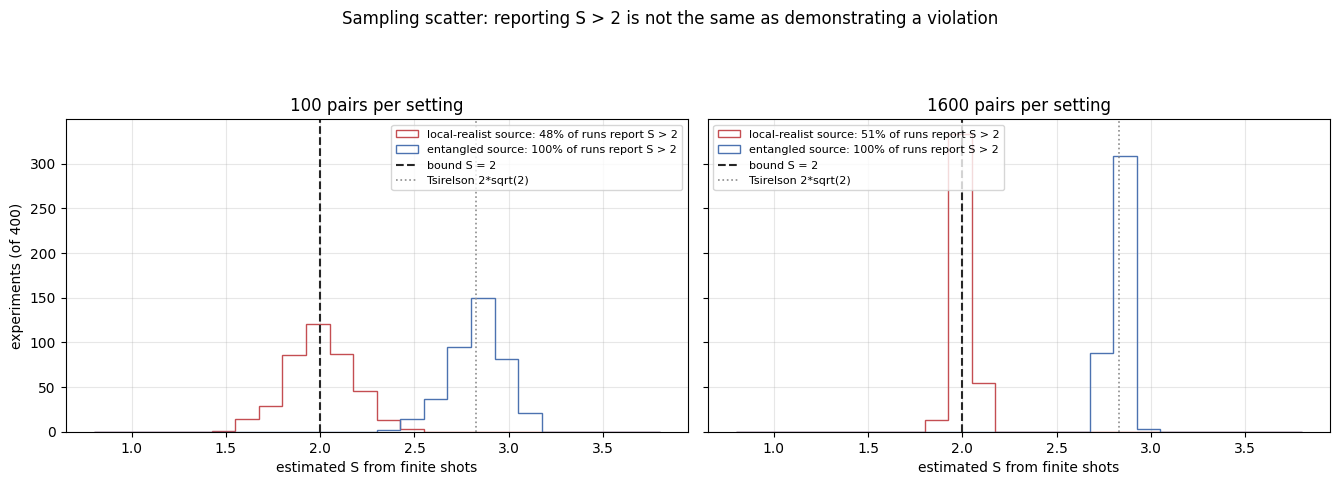

In [8]:
def classical_joint(a: float, b: float, shots: int, seed: int) -> dict:
    """Sample the shared-angle model directly: draw lambda, then deterministic +/-1 answers."""
    gen = np.random.default_rng(seed)
    lam = gen.uniform(0, 2 * math.pi, shots)
    alpha = np.where(np.cos(a - lam) >= 0, 1, -1)
    beta = np.where(np.cos(b - lam) >= 0, 1, -1)
    ab = (alpha * beta).astype(float)
    counts = np.array([int(((alpha == 1) & (beta == 1)).sum()), int(((alpha == 1) & (beta == -1)).sum()),
                       int(((alpha == -1) & (beta == 1)).sum()), int(((alpha == -1) & (beta == -1)).sum())])
    return {"counts": counts, "E": float(ab.mean()),
            "sigma": float(ab.std(ddof=1) / math.sqrt(shots)), "shots": shots}


def classical_experiment(angles, shots, seed):
    a, ap, b, bp = angles
    runs = [classical_joint(a, b, shots, seed), classical_joint(a, bp, shots, seed + 1),
            classical_joint(ap, b, shots, seed + 2), classical_joint(ap, bp, shots, seed + 3)]
    s_hat = runs[0]["E"] + runs[1]["E"] + runs[2]["E"] - runs[3]["E"]
    return {"runs": runs, "S": abs(s_hat),
            "sigma": math.sqrt(sum(r["sigma"] ** 2 for r in runs))}


print(f"{'setting':<12} {'N(++)':>7} {'N(+-)':>7} {'N(-+)':>7} {'N(--)':>7} {'E_hat':>8}")
for label, run in zip(["(a,b)", "(a,b')", "(a',b)", "(a',b')"], classical_experiment((A, AP, B, BP), 4000, 99)["runs"]):
    c = run["counts"]
    print(f"{label:<12} {c[0]:>7} {c[1]:>7} {c[2]:>7} {c[3]:>7} {run['E']:>+8.4f}")

quantum_S = run_experiment(rho_phi_plus, (A, AP, B, BP), 4000, 7)
classical_S = classical_experiment((A, AP, B, BP), 4000, 7)
print(f"\nquantum source   : S_hat = {quantum_S['S']:.4f} +- {quantum_S['sigma']:.4f}")
print(f"hidden-variable  : S_hat = {classical_S['S']:.4f}")
print("both give Alice 50/50 marginals; only the coincidence pattern separates them.")

# Now the honest part: repeat the whole experiment many times. A local-realist source sits
# exactly ON the bound, so luck alone puts half its runs above 2 at any shot count.
print("\n400 repeats of the whole experiment, same pipeline, two sources")
print(f"{'shots/':>8} {'lr mean S':>10} {'lr S>2':>8} {'lr 3sigma':>10}   "
      f"{'q mean S':>10} {'q S>2':>8} {'q 3sigma':>10}")
for shots in (25, 100, 400, 1600):
    c = [classical_experiment((A, AP, B, BP), shots, seed) for seed in range(400)]
    q = [run_experiment(rho_phi_plus, (A, AP, B, BP), shots, seed) for seed in range(400)]

    def stats(runs):
        s = np.array([r["S"] for r in runs])
        z = np.array([(r["S"] - 2) / r["sigma"] for r in runs])
        return s.mean(), np.mean(s > 2), np.mean(z > 3)

    cm, cp, cz = stats(c)
    qm, qp, qz = stats(q)
    print(f"{shots:>8} {cm:>10.3f} {cp:>8.0%} {cz:>10.1%}   {qm:>10.3f} {qp:>8.0%} {qz:>10.1%}")
print("lr = local-realist source (S can never exceed 2), q = entangled source")
print("lr S>2 stays near 50%: sitting on the bound means the coin decides which side you land on.")
print("lr 3sigma stays tiny: the excess over 2 shrinks with N exactly like sigma does,")
print("while for the entangled source it grows, so requiring significance separates them.")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.9), sharey=True)
for ax, shots, loc in zip(axes, (100, 1600), ("upper right", "upper left")):
    c = np.array([classical_experiment((A, AP, B, BP), shots, seed)["S"] for seed in range(400)])
    q = np.array([run_experiment(rho_phi_plus, (A, AP, B, BP), shots, seed)["S"] for seed in range(400)])
    ax.hist(c, bins=24, range=(0.8, 3.8), histtype="step", lw=2, color="#c44e52",
            label=f"local-realist source: {np.mean(c > 2):.0%} of runs report S > 2")
    ax.hist(q, bins=24, range=(0.8, 3.8), histtype="step", lw=2, color="#4c72b0",
            label=f"entangled source: {np.mean(q > 2):.0%} of runs report S > 2")
    ax.axvline(2, color="0.15", lw=1.5, ls="--", label="bound S = 2")
    ax.axvline(2 * math.sqrt(2), color="0.55", lw=1.2, ls=":", label="Tsirelson 2*sqrt(2)")
    ax.set_xlabel("estimated S from finite shots")
    ax.set_title(f"{shots} pairs per setting")
    ax.legend(fontsize=8, loc=loc)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("experiments (of 400)")
fig.suptitle("Sampling scatter: reporting S > 2 is not the same as demonstrating a violation")
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

---
## Part 5 · The CHSH game (same inequality, friendlier units)

Alice and Bob receive random bits `x, y`, must return bits `a, b`, and win when
`a ⊕ b = x·y`. They cannot communicate after the questions arrive, but they may share
qubits — or a written rulebook — in advance.

* Best **classical** strategy: win probability `3/4`. Not a guess: there are only 16
  deterministic local rulebooks (each player maps two possible questions to two bits), so
  we score every one of them exactly. Shared randomness is just a mixture over those 16,
  so it cannot do better either.
* Best **quantum** with a Bell pair: `cos²(π/8) ≈ 0.8536`.

The link is exact: `P_win = 1/2 + S/8`, equivalently `S = 8·P_win − 4`, so `S = 2` ↔ 75% and
`S = 2√2` ↔ 85.4%. Simulating the game is the clearest way to see that this is a *task*
advantage, not a philosophy argument.


deterministic local strategies, scored exactly over the four question pairs:
(notation: a(0),a(1) = Alice's answers to questions 0 and 1, likewise for b)
  win 0.750  x 8  e.g. a=(0, 0) b=(0, 0), a=(0, 0) b=(0, 1), a=(0, 1) b=(0, 0)
  win 0.250  x 8  e.g. a=(0, 0) b=(1, 0), a=(0, 0) b=(1, 1), a=(0, 1) b=(0, 1)
  best possible classically = 0.7500  (shared randomness is a mixture of these, so it cannot beat it)
pairs=   400  classical win = 0.7725  quantum win = 0.8750  (theory 0.7500 / 0.8536)
pairs=  4000  classical win = 0.7505  quantum win = 0.8532  (theory 0.7500 / 0.8536)
pairs= 40000  classical win = 0.7497  quantum win = 0.8523  (theory 0.7500 / 0.8536)

S from the game: classical S = 8*0.75 - 4 = 2.000, quantum S = 8*cos^2(pi/8) - 4 = 2.828427


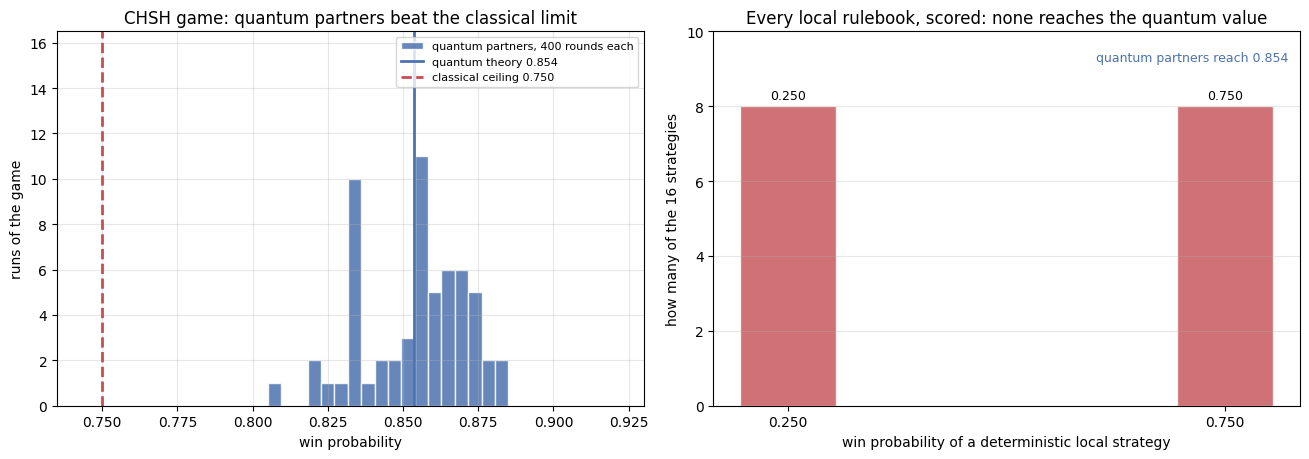

In [9]:
def play_game(strategy, pairs: int, seed: int) -> float:
    """strategy(x, y) -> (a, b). Returns the win fraction."""
    gen = np.random.default_rng(seed)
    xs, ys = gen.integers(0, 2, pairs), gen.integers(0, 2, pairs)
    wins = 0
    for x, y in zip(xs, ys):
        a, b = strategy(int(x), int(y))
        wins += int((a ^ b) == (x * y))
    return wins / pairs


def make_classical_strategy(table_a, table_b):
    """Local strategy: Alice answers table_a[x], Bob answers table_b[y].
    Neither answer may depend on the other player's question - that is the whole rule."""
    return lambda x, y: (table_a[x], table_b[y])


# Exhaustive check that 3/4 is the classical ceiling: score all 16 local strategies.
from itertools import product as _product
local_scores = {(ta, tb): sum(int((ta[x] ^ tb[y]) == (x * y)) for x, y in _product((0, 1), repeat=2)) / 4
         for ta in _product((0, 1), repeat=2) for tb in _product((0, 1), repeat=2)}
best_rate = max(local_scores.values())
print("deterministic local strategies, scored exactly over the four question pairs:")
print("(notation: a(0),a(1) = Alice's answers to questions 0 and 1, likewise for b)")
for rate in sorted(set(local_scores.values()), reverse=True):
    how = [f"a={ta} b={tb}" for (ta, tb), v in local_scores.items() if v == rate][:3]
    print(f"  win {rate:.3f}  x{sum(1 for v in local_scores.values() if v == rate):>2}  e.g. {', '.join(how)}")
print(f"  best possible classically = {best_rate:.4f}  (shared randomness is a mixture of these, so it cannot beat it)")


classical_strategy = make_classical_strategy((0, 0), (0, 0))


# Quantum strategy: both measure their half of |Phi+> at an angle set by their question bit.
# x selects Alice's CHSH setting (a, a'), y selects Bob's (b, b'). The two answers come from
# one joint draw out of the shared pair, which is exactly what no local table can imitate.
ALICE_ANGLE = {0: A, 1: AP}
BOB_ANGLE = {0: B, 1: BP}


def make_quantum_strategy(rho: np.ndarray, seed: int = 0):
    gen = np.random.default_rng(seed)

    def strategy(x, y):
        p = joint_probabilities(rho, ALICE_ANGLE[x], BOB_ANGLE[y])
        p = np.clip(p, 0, None)
        p = p / p.sum()
        a, b = SIGNS[gen.choice(4, p=p)]
        return int((1 - a) // 2), int((1 - b) // 2)  # outcome +1 -> bit 0

    return strategy


for pairs in (400, 4000, 40000):
    pc = play_game(classical_strategy, pairs, 5)
    pq = play_game(make_quantum_strategy(rho_phi_plus, 6), pairs, 7)
    print(f"pairs={pairs:>6}  classical win = {pc:.4f}  quantum win = {pq:.4f}  "
          f"(theory 0.7500 / {math.cos(math.pi / 8) ** 2:.4f})")

print(f"\nS from the game: classical S = 8*0.75 - 4 = {8 * 0.75 - 4:.3f}, "
      f"quantum S = 8*cos^2(pi/8) - 4 = {8 * math.cos(math.pi / 8) ** 2 - 4:.6f}")

fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.7))
trials = [play_game(make_quantum_strategy(rho_phi_plus, s), 400, s + 100) for s in range(60)]
axes[0].hist(trials, bins=18, color="#4c72b0", alpha=0.85, edgecolor="white",
             label="quantum partners, 400 rounds each")
axes[0].axvline(math.cos(math.pi / 8) ** 2, color="#4c72b0", lw=2, label="quantum theory 0.854")
axes[0].axvline(0.75, color="#c44e52", lw=2, ls="--", label="classical ceiling 0.750")
axes[0].set_xlabel("win probability")
axes[0].set_ylabel("runs of the game")
axes[0].set_xlim(0.735, 0.93)
axes[0].set_ylim(0, np.histogram(trials, bins=18)[0].max() * 1.5)
axes[0].set_title("CHSH game: quantum partners beat the classical limit")
axes[0].legend(fontsize=8, loc="upper right")
axes[0].grid(alpha=0.3)

values = sorted(set(local_scores.values()))
counts = [sum(1 for v in local_scores.values() if v == val) for val in values]
bars = axes[1].bar([f"{v:.3f}" for v in values], counts, width=0.22,
                   color="#c44e52", alpha=0.8, edgecolor="white")
for bar, val in zip(bars, values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2, f"{val:.3f}",
                 ha="center", fontsize=9)
axes[1].set_xlabel("win probability of a deterministic local strategy")
axes[1].set_ylabel("how many of the 16 strategies")
axes[1].set_title("Every local rulebook, scored: none reaches the quantum value")
axes[1].set_ylim(0, max(counts) * 1.25)
axes[1].text(0.98, 0.92, f"quantum partners reach {math.cos(math.pi / 8) ** 2:.3f}",
             transform=axes[1].transAxes, ha="right", fontsize=9, color="#4c72b0")
axes[1].grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

---
## Part 6 · Ideal versus noisy

Real sources are not pure `|Φ⁺⟩`. Every channel below is implemented as a sum over Kraus
operators, `ρ → Σ_k K_k ρ K_k†`, so the noise is applied to the state, not pasted onto the
answer.

| Channel | Kraus operators | Effect on `E` |
|---|---|---|
| Depolarising, prob `p` | `{√(1−p)·I, √(p/3)·X, √(p/3)·Y, √(p/3)·Z}` | shrinks the Bloch vector by `1 − 4p/3` |
| Dephasing, prob `p` | `{√(1−p)·I, √p·Z}` | kills `X`-type correlations only |
| Bit flip, prob `p` | `{√(1−p)·I, √p·X}` | flips `Z`-type correlations |
| Measurement error, prob `ε` | applied to the outcome | multiplies every `E` by `(1 − 2ε)²` |

The violation survives until the *product* of all those factors drops below `1/√2 ≈ 0.707`.
For white noise on the pair that is `p* = 1 − 1/√2 ≈ 0.293`; for symmetric detector error
`ε* = (1 − 2^(−1/4))/2 ≈ 8.0%`. Both come out of the simulation, and we check them against
the formula.


In [10]:
def apply_kraus(rho: np.ndarray, kraus: list) -> np.ndarray:
    out = np.zeros_like(rho)
    for K in kraus:
        out += K @ rho @ K.conj().T
    return out


def on_qubit(kraus: list, qubit: int, n: int) -> list:
    """Lift a 1-qubit channel onto qubit `qubit` of an n-qubit density matrix."""
    return [np.kron(np.eye(2**qubit), np.kron(K, np.eye(2 ** (n - 1 - qubit)))) for K in kraus]


def depolarising(p: float) -> list:
    return [math.sqrt(1 - p) * I2] + [math.sqrt(p / 3) * M for M in (X, Y, Z)]


def dephasing(p: float) -> list:
    return [math.sqrt(1 - p) * I2, math.sqrt(p) * Z]


def bit_flip(p: float) -> list:
    return [math.sqrt(1 - p) * I2, math.sqrt(p) * X]


def noisy_state(channel, p: float, both: bool = True) -> np.ndarray:
    rho = density_matrix(BELL["Phi+"])
    for q in (range(2) if both else [0]):
        rho = apply_kraus(rho, on_qubit(channel(p), q, 2))
    return rho


def measured_S(rho, angles=(A, AP, B, BP), eps: float = 0.0) -> float:
    """S from the density matrix, with detector misidentification probability eps."""
    scale = (1 - 2 * eps) ** 2
    S, _ = chsh(rho, *angles)
    return S * scale


# Sanity: channels are trace preserving and keep the state Hermitian.
for name, channel in [("depolarising", depolarising), ("dephasing", dephasing), ("bit_flip", bit_flip)]:
    rho = noisy_state(channel, 0.25)
    print(f"{name:<13}: trace {rho.trace().real:.6f}, hermitian {np.allclose(rho, rho.conj().T)}, "
          f"purity {np.trace(rho @ rho).real:.4f}, S = {measured_S(rho):.4f}")

print("\n--- white noise on the pair: rho -> (1-p)|Phi+><Phi+| + p I/4 ---")
print(f"{'p':>6} {'fidelity':>9} {'S':>8} {'violates 2?':>12}")
for p in (0.0, 0.05, 0.10, 0.20, 0.29, 0.293, 0.35, 0.50):
    rho_w = (1 - p) * rho_phi_plus + p * np.eye(4) / 4
    S = measured_S(rho_w)
    fid = float(np.real(np.trace(rho_w @ rho_phi_plus)))
    print(f"{p:>6.3f} {fid:>9.3f} {S:>8.4f} {str(S > 2):>12}")
p_star = 1 - 1 / math.sqrt(2)
print(f"threshold from the formula p* = 1 - 1/sqrt(2) = {p_star:.4f}; "
      f"scan says S(p*) = {measured_S((1 - p_star) * rho_phi_plus + p_star * np.eye(4) / 4):.6f}")

print("\n--- detector (readout) error only, ideal source ---")
print(f"{'eps':>6} {'S':>8} {'violates 2?':>12}")
for eps in (0.0, 0.02, 0.05, 0.079, 0.09, 0.12, 0.2):
    S = measured_S(rho_phi_plus, eps=eps)
    print(f"{eps:>6.3f} {S:>8.4f} {str(S > 2):>12}")
eps_star = (1 - 2 ** -0.25) / 2
print(f"threshold from the formula eps* = (1 - 2^-1/4)/2 = {eps_star:.4f}; "
      f"S(eps*) = {measured_S(rho_phi_plus, eps=eps_star):.6f}")

print("\n--- which channel hurts most at the same error probability p = 0.15 ---")
for name, channel in [("depolarising", depolarising), ("dephasing", dephasing), ("bit_flip", bit_flip)]:
    print(f"  {name:<13} S = {measured_S(noisy_state(channel, 0.15)):.4f}")

depolarising : trace 1.000000, hermitian True, purity 0.3981, S = 1.2571
dephasing    : trace 1.000000, hermitian True, purity 0.5312, S = 1.7678
bit_flip     : trace 1.000000, hermitian True, purity 0.5312, S = 1.7678

--- white noise on the pair: rho -> (1-p)|Phi+><Phi+| + p I/4 ---
     p  fidelity        S  violates 2?
 0.000     1.000   2.8284         True
 0.050     0.962   2.6870         True
 0.100     0.925   2.5456         True
 0.200     0.850   2.2627         True
 0.290     0.782   2.0082         True
 0.293     0.780   1.9997        False
 0.350     0.737   1.8385        False
 0.500     0.625   1.4142        False
threshold from the formula p* = 1 - 1/sqrt(2) = 0.2929; scan says S(p*) = 2.000000

--- detector (readout) error only, ideal source ---
   eps        S  violates 2?
 0.000   2.8284         True
 0.020   2.6067         True
 0.050   2.2910         True
 0.079   2.0053         True
 0.090   1.9018        False
 0.120   1.6337        False
 0.200   1.0182        F

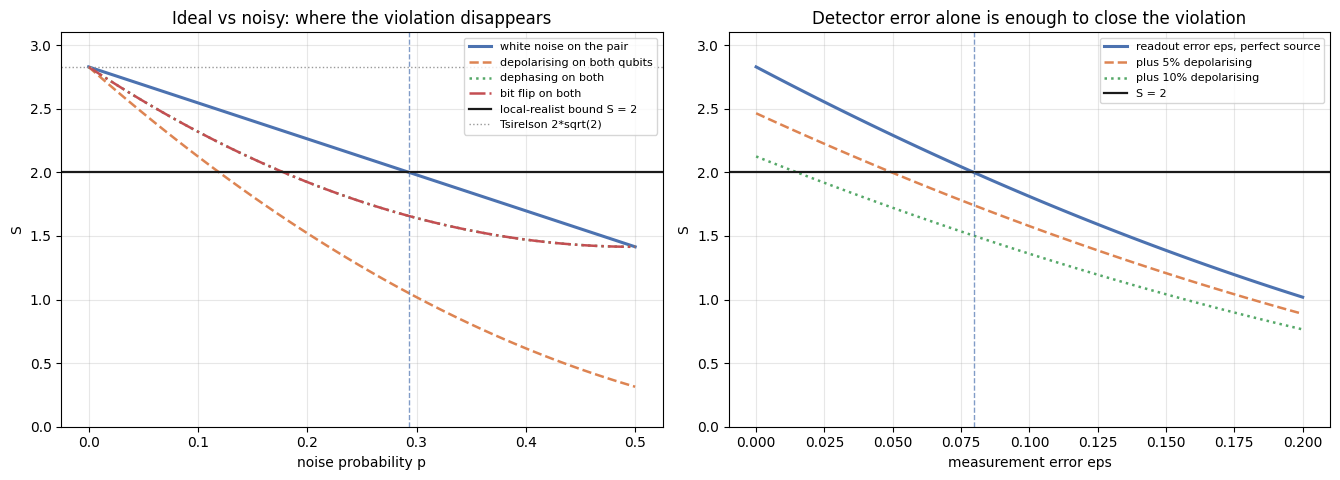

readout-only threshold eps* = 0.0796  (S crosses 2 there)
white-noise threshold p*    = 0.2929

DEVICE BUDGET (|Phi+> source, CHSH settings)
scenario                            S_exact  S_hat(4k shots)    verdict
ideal                                2.8284           2.8070   violates
5% depolarising per qubit            2.4639           2.4510   violates
10% depolarising per qubit           2.1245           2.1185   violates
15% depolarising per qubit           1.8102           1.8085  classical
10% depolarising + 4% readout        1.7981           1.7990  classical
25% depolarising + 4% readout        1.0640           1.0490  classical
20% dephasing + 6% readout           1.4894           1.4930  classical
ideal source, 8% readout             1.9957           1.9985  classical

The two columns answer the same question two different ways:
  S_exact scales each correlation by (1-2*eps)^2,
  S_hat actually misreports detector bits, one pair at a time.


In [11]:
# Sweep the noise parameters and plot the death of the violation.
ps = np.linspace(0, 0.5, 120)
S_dep = [measured_S(noisy_state(depolarising, p)) for p in ps]
S_deph = [measured_S(noisy_state(dephasing, p)) for p in ps]
S_flip = [measured_S(noisy_state(bit_flip, p)) for p in ps]
S_white = [measured_S((1 - p) * rho_phi_plus + p * np.eye(4) / 4) for p in ps]

es = np.linspace(0, 0.2, 120)
S_det = [measured_S(rho_phi_plus, eps=e) for e in es]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.9))
axes[0].plot(ps, S_white, lw=2.2, color="#4c72b0", label="white noise on the pair")
axes[0].plot(ps, S_dep, lw=1.8, ls="--", color="#dd8452", label="depolarising on both qubits")
axes[0].plot(ps, S_deph, lw=1.8, ls=":", color="#55a868", label="dephasing on both")
axes[0].plot(ps, S_flip, lw=1.8, ls="-.", color="#c44e52", label="bit flip on both")
axes[0].axhline(2, color="0.1", lw=1.6, label="local-realist bound S = 2")
axes[0].axhline(2 * math.sqrt(2), color="0.6", lw=1, ls=":", label="Tsirelson 2*sqrt(2)")
axes[0].axvline(p_star, color="#4c72b0", lw=1, ls="--", alpha=0.7)
axes[0].set_xlabel("noise probability p")
axes[0].set_ylabel("S")
axes[0].set_ylim(0, 3.1)
axes[0].set_title("Ideal vs noisy: where the violation disappears")
axes[0].legend(fontsize=8, loc="upper right")
axes[0].grid(alpha=0.3)

axes[1].plot(es, S_det, lw=2.2, color="#4c72b0", label="readout error eps, perfect source")
axes[1].plot(es, [measured_S(noisy_state(depolarising, 0.05), eps=e) for e in es],
             lw=1.8, ls="--", color="#dd8452", label="plus 5% depolarising")
axes[1].plot(es, [measured_S(noisy_state(depolarising, 0.10), eps=e) for e in es],
             lw=1.8, ls=":", color="#55a868", label="plus 10% depolarising")
axes[1].axhline(2, color="0.1", lw=1.6, label="S = 2")
axes[1].axvline(eps_star, color="#4c72b0", lw=1, ls="--", alpha=0.7)
axes[1].set_xlabel("measurement error eps")
axes[1].set_ylabel("S")
axes[1].set_ylim(0, 3.1)
axes[1].set_title("Detector error alone is enough to close the violation")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

print(f"readout-only threshold eps* = {eps_star:.4f}  (S crosses 2 there)")
print(f"white-noise threshold p*    = {p_star:.4f}")

# A plausible device budget: everything wrong at once, then measured with finite shots.
print("\nDEVICE BUDGET (|Phi+> source, CHSH settings)")
print(f"{'scenario':<34} {'S_exact':>8} {'S_hat(4k shots)':>16} {'verdict':>10}")
scenarios = [
    ("ideal", rho_phi_plus, 0.0),
    ("5% depolarising per qubit", noisy_state(depolarising, 0.05), 0.0),
    ("10% depolarising per qubit", noisy_state(depolarising, 0.10), 0.0),
    ("15% depolarising per qubit", noisy_state(depolarising, 0.15), 0.0),
    ("10% depolarising + 4% readout", noisy_state(depolarising, 0.10), 0.04),
    ("25% depolarising + 4% readout", noisy_state(depolarising, 0.25), 0.04),
    ("20% dephasing + 6% readout", noisy_state(dephasing, 0.20), 0.06),
    ("ideal source, 8% readout", rho_phi_plus, 0.08),
]
for label, rho, eps in scenarios:
    s_exact = measured_S(rho, eps=eps)
    shot = run_experiment(rho, (A, AP, B, BP), 4000, 11, eps=eps)
    print(f"{label:<34} {s_exact:>8.4f} {shot['S']:>16.4f} "
          f"{('violates' if shot['S'] > 2 else 'classical'):>10}")

print("\nThe two columns answer the same question two different ways:")
print("  S_exact scales each correlation by (1-2*eps)^2,")
print("  S_hat actually misreports detector bits, one pair at a time.")

---
## Part 7 · Self-tests

The checks that matter here: the Bell states are orthonormal and have maximally mixed
marginals; the analyser identifies all four; `E` computed from projectors equals `E`
computed from the operator trace; the closed forms `cos(a∓b)` / `−cos(a±b)` hold for all
four states; the standard settings give exactly `2√2` and **each** Bell state reaches it
with its own searched settings; **no** angle quadruple in a dense scan lets the
hidden-variable model exceed 2; the noise channels are trace-preserving and reproduce the
analytic thresholds `p* = 1 − 1/√2` and `ε* = (1 − 2^{−1/4})/2`; flipping detector bits one
pair at a time in the sampler gives the same suppression as the `(1 − 2ε)²` shortcut; and
the finite-shot estimator concentrates on the true value as `1/√N`.


In [12]:
def run_self_tests(verbose: bool = True):
    ok = []

    def check(name, condition):
        if not condition:
            raise AssertionError(f"FAILED: {name}")
        ok.append(name)

    # Bell states
    for name, psi in BELL.items():
        check(f"|{name}> normalised", math.isclose(np.linalg.norm(psi), 1.0, abs_tol=1e-12))
        rho = density_matrix(psi)
        check(f"|{name}> pair is pure", math.isclose(np.trace(rho @ rho).real, 1.0, abs_tol=1e-12))
        check(f"|{name}> marginals are I/2",
              np.allclose(partial_trace(rho, [0], 2), I2 / 2) and np.allclose(partial_trace(rho, [1], 2), I2 / 2))
        check(f"|{name}> marginals are random for every setting",
              all(math.isclose(joint_probabilities(rho, t, 0.0)[0] + joint_probabilities(rho, t, 0.0)[2], 0.5, abs_tol=1e-12)
                  for t in (0.0, 0.4, 1.1, 2.5)))
    check("Bell states orthogonal", all(abs(np.vdot(BELL[a], BELL[b])) < 1e-12
                                       for a in BELL for b in BELL if a != b))
    check("Phi+ circuit matches the closed form", np.allclose(BELL["Phi+"], np.array([1, 0, 0, 1]) / math.sqrt(2)))
    check("Psi- circuit matches the closed form", np.allclose(BELL["Psi-"], np.array([0, 1, -1, 0]) / math.sqrt(2)))

    # analyser
    check("analyser maps each Bell state to one bit string",
          all(int(np.argmax(np.abs(bell_analyser(psi)))) == int(bits, 2)
              for bits, name in [("00", "Phi+"), ("10", "Phi-"), ("01", "Psi+"), ("11", "Psi-")]
              for psi in [BELL[name]]))

    # correlations
    check("joint probabilities sum to 1",
          math.isclose(sum(joint_probabilities(rho_phi_plus, 0.3, 1.2)), 1.0, abs_tol=1e-12))
    closed = {"Phi+": lambda a, b: math.cos(a - b), "Phi-": lambda a, b: math.cos(a + b),
              "Psi+": lambda a, b: -math.cos(a + b), "Psi-": lambda a, b: -math.cos(a - b)}
    for name, formula in closed.items():
        rho = density_matrix(BELL[name])
        check(f"{name} closed form everywhere",
              all(abs(correlation(rho, a, b) - formula(a, b)) < 1e-9
                  for a in (0.0, 0.37, 1.1, 2.4, -0.9) for b in (0.0, 0.61, 1.9, -1.3)))
    check("E is symmetric in its arguments",
          all(abs(correlation(rho_phi_plus, a, b) - correlation(rho_phi_plus, b, a)) < 1e-12
              for a, b in [(0.2, 1.0), (0.0, math.pi / 4), (1.3, -0.4)]))
    check("E stays within [-1, 1]",
          all(abs(correlation(rho_phi_plus, a, b)) <= 1 + 1e-12
              for a in np.linspace(0, 2 * math.pi, 11) for b in np.linspace(0, 2 * math.pi, 11)))
    check("singlet anti-correlates at equal settings", math.isclose(correlation(density_matrix(BELL["Psi-"]), 0.7, 0.7), -1.0, abs_tol=1e-12))
    check("Phi+ correlates at equal settings", math.isclose(correlation(rho_phi_plus, 0.7, 0.7), 1.0, abs_tol=1e-12))
    check("orthogonal settings give zero correlation", math.isclose(correlation(rho_phi_plus, 0.0, math.pi / 2), 0.0, abs_tol=1e-12))

    # CHSH
    check("standard settings reach Tsirelson", math.isclose(chsh(rho_phi_plus, A, AP, B, BP)[0], 2 * math.sqrt(2), abs_tol=1e-12))
    for name in BELL:
        check(f"{name} violates with its own settings",
              chsh(density_matrix(BELL[name]), *settings[name])[0] > 2 + 1e-9)
    check("all four Bell states cap at Tsirelson",
          all(math.isclose(chsh(density_matrix(BELL[n]), *settings[n])[0], 2 * math.sqrt(2), abs_tol=1e-9) for n in BELL))
    check("product state never violates",
          all(chsh(density_matrix(apply_unitary(zero_state(2), H, [0], 2)), a, ap, b, bp)[0] <= 2 + 1e-12
              for a, ap, b, bp in [(A, AP, B, BP), (0.0, 0.5, 0.2, 0.9), (1.0, 2.0, 0.3, 0.7)]))
    coarse = np.linspace(0, 2 * math.pi, 13, endpoint=False)
    check("hidden-variable model never exceeds 2 on a dense scan",
          max(classical_chsh(a, ap, b, bp) for a in coarse for ap in coarse for b in coarse for bp in coarse) <= 2 + 1e-12)
    check("hidden-variable model saturates 2 at the CHSH settings", math.isclose(classical_chsh(A, AP, B, BP), 2.0, abs_tol=1e-12))
    check("grid scan quantum max is Tsirelson", math.isclose(quantum_scan.max(), 2 * math.sqrt(2), abs_tol=1e-9))
    check("grid scan classical max is the bound", math.isclose(classical_scan.max(), 2.0, abs_tol=1e-9))

    # CHSH game
    check("16 local rulebooks, none beats 3/4", len(local_scores) == 16 and max(local_scores.values()) == 0.75)
    check("classical game win rate is 3/4", math.isclose(play_game(classical_strategy, 200000, 3), 0.75, abs_tol=0.004))
    check("quantum game win rate is cos^2(pi/8)", math.isclose(play_game(make_quantum_strategy(rho_phi_plus, 4), 200000, 5),
                                                              math.cos(math.pi / 8) ** 2, abs_tol=0.004))
    check("S and win probability agree", math.isclose(8 * math.cos(math.pi / 8) ** 2 - 4, 2 * math.sqrt(2), abs_tol=1e-12))

    # noise channels
    for name, channel in [("depolarising", depolarising), ("dephasing", dephasing), ("bit_flip", bit_flip)]:
        for p in (0.0, 0.1, 0.5):
            rho = noisy_state(channel, p)
            check(f"{name} p={p} trace preserving", math.isclose(rho.trace().real, 1.0, abs_tol=1e-12))
            check(f"{name} p={p} hermitian", np.allclose(rho, rho.conj().T, atol=1e-12))
            check(f"{name} p={p} positive", np.min(np.linalg.eigvalsh(rho)) > -1e-12)
    check("no noise reproduces the ideal S", math.isclose(measured_S(noisy_state(depolarising, 0.0)), 2 * math.sqrt(2), abs_tol=1e-12))
    check("full depolarising gives the maximally mixed state",
          np.allclose(noisy_state(depolarising, 0.75), np.eye(4) / 4, atol=1e-12))
    check("full depolarising kills all correlation", math.isclose(measured_S(noisy_state(depolarising, 0.75)), 0.0, abs_tol=1e-9))
    check("white-noise threshold p*", math.isclose(measured_S((1 - p_star) * rho_phi_plus + p_star * np.eye(4) / 4), 2.0, abs_tol=1e-9))
    check("white noise just below p* still violates",
          measured_S((1 - (p_star - 0.01)) * rho_phi_plus + (p_star - 0.01) * np.eye(4) / 4) > 2.0)
    check("white noise just above p* does not",
          measured_S((1 - (p_star + 0.01)) * rho_phi_plus + (p_star + 0.01) * np.eye(4) / 4) < 2.0)
    check("readout threshold eps*", math.isclose(measured_S(rho_phi_plus, eps=eps_star), 2.0, abs_tol=1e-9))
    check("readout error scales S by (1-2eps)^2",
          math.isclose(measured_S(rho_phi_plus, eps=0.03), 2 * math.sqrt(2) * 0.94 ** 2, abs_tol=1e-12))
    check("dephasing hurts less than depolarising at p=0.15",
          measured_S(noisy_state(dephasing, 0.15)) > measured_S(noisy_state(depolarising, 0.15)))
    check("noise on one qubit only is milder than on both",
          measured_S(noisy_state(depolarising, 0.1, both=False)) > measured_S(noisy_state(depolarising, 0.1, both=True)))

    # finite shots
    for shots in (2000, 60000):
        res = run_experiment(rho_phi_plus, (A, AP, B, BP), shots, 17)
        check(f"shot estimate within 3 sigma at {shots}", abs(res["S"] - 2 * math.sqrt(2)) < 3 * res["sigma"])
    check("sigma shrinks as 1/sqrt(N)",
          run_experiment(rho_phi_plus, (A, AP, B, BP), 4000, 1)["sigma"]
          > 3 * run_experiment(rho_phi_plus, (A, AP, B, BP), 40000, 1)["sigma"])
    check("counts add up to shots", sum(run_experiment(rho_phi_plus, (A, AP, B, BP), 1234, 2)["runs"][0]["counts"]) == 1234)
    check("sampled marginals are 50/50",
          all(abs((r["counts"][0] + r["counts"][1]) / r["shots"] - 0.5) < 0.008
              for r in run_experiment(rho_phi_plus, (A, AP, B, BP), 40000, 3)["runs"]))
    check("readout flips in the sampler match the (1-2eps)^2 formula",
          all(abs(sample_setting(rho_phi_plus, a, b, 400000, 21, eps=0.05)["E"]
                  - (1 - 2 * 0.05) ** 2 * correlation(rho_phi_plus, a, b)) < 0.01
              for a, b in [(A, B), (A, BP), (AP, B)]))
    check("readout flips leave the marginals at 50/50",
          abs(sum(sample_setting(rho_phi_plus, A, B, 200000, 22, eps=0.1)["counts"][:2]) / 200000 - 0.5) < 0.005)
    check("hidden-variable sampler matches its correlation formula",
          abs(classical_experiment((A, AP, B, BP), 200000, 42)["S"] - 2.0) < 0.02)
    check("hidden-variable marginals are 50/50",
          all(abs((r["counts"][0] + r["counts"][1]) / r["shots"] - 0.5) < 0.008
              for r in classical_experiment((A, AP, B, BP), 40000, 8)["runs"]))
    lr = [classical_experiment((A, AP, B, BP), 400, seed) for seed in range(200)]
    qm = [run_experiment(rho_phi_plus, (A, AP, B, BP), 400, seed) for seed in range(200)]
    check("a source sitting on the bound straddles it", 0.3 < np.mean([r["S"] > 2 for r in lr]) < 0.7)
    check("its significance stays small while the entangled source's is large",
          np.mean([(r["S"] - 2) / r["sigma"] for r in lr]) < 1.0
          < 5.0 < np.mean([(r["S"] - 2) / r["sigma"] for r in qm]))
    check("significance of a real violation grows with N",
          np.mean([(r["S"] - 2) / r["sigma"] for r in
                   (run_experiment(rho_phi_plus, (A, AP, B, BP), 6400, seed) for seed in range(60))])
          > 3 * np.mean([(r["S"] - 2) / r["sigma"] for r in qm[:60]]))

    if verbose:
        print(f"all {len(ok)} checks passed")
    return ok


_ = run_self_tests()

all 94 checks passed


---
## Part 8 · Optional: cross-check with Qiskit

Qiskit already contains Bell circuits, Pauli expectation values and quantum channels, so it
is the right second opinion. We compare, on the same states and settings:

1. the four Bell state vectors (endianness converted, as in the first notebook);
2. `E(a,b)` against `⟨M(a) ⊗ M(b)⟩` computed from Qiskit's own statevector;
3. `S` for the standard settings, and the noisy state against
   `DensityMatrix(...).evolve(Kraus(our_kraus_operators))` — same noise operators, two
   different pieces of machinery.

Everything above runs without these two cells.


In [13]:
try:
    import qiskit

    print(f"Qiskit {qiskit.__version__} already available")
except ImportError:
    print("installing qiskit (a minute in Colab)...")
    %pip install -q qiskit

from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, Statevector, DensityMatrix, Pauli, Kraus

print("qiskit import ok")

installing qiskit (a minute in Colab)...
qiskit import ok


In [14]:
def flip_qubit_order(vec: np.ndarray, n: int) -> np.ndarray:
    """Our big-endian ordering -> Qiskit's little-endian (and back)."""
    perm = np.array([int(format(k, f"0{n}b")[::-1], 2) for k in range(2**n)])
    return vec[perm]


def qiskit_bell(name: str) -> np.ndarray:
    qc = QuantumCircuit(2)
    qc.h(0)
    qc.cx(0, 1)
    if name == "Phi-":
        qc.z(0)
    elif name == "Psi+":
        qc.x(1)
    elif name == "Psi-":
        qc.x(0)
        qc.z(0)
    return np.asarray(Statevector(qc).data, dtype=complex)


print("Bell state vectors vs Qiskit Statevector (ray overlap, global phase ignored):")
for name in BELL:
    theirs, ours = qiskit_bell(name), flip_qubit_order(BELL[name], 2)
    overlap = abs(np.vdot(theirs, ours))
    print(f"  |{name}>  |<qiskit|ours>| = {overlap:.12f}  {'match' if overlap > 1 - 1e-12 else 'MISMATCH'}")
    assert overlap > 1 - 1e-12

# E(a,b) against Qiskit's expectation value of the two-qubit observable.
def qiskit_correlation(name: str, a: float, b: float) -> float:
    obs = np.kron(observable(a), observable(b))
    return float(np.real(np.vdot(qiskit_bell(name), obs @ qiskit_bell(name))))


print("\nE(a,b) for the standard CHSH settings:")
print(f"{'setting':<12} {'ours':>12} {'qiskit':>12} {'difference':>12}")
for label, (a, b) in zip(["(a,b)", "(a,b')", "(a',b)", "(a',b')"], [(A, B), (A, BP), (AP, B), (AP, BP)]):
    ours, theirs = correlation(rho_phi_plus, a, b), qiskit_correlation("Phi+", a, b)
    print(f"{label:<12} {ours:>+12.9f} {theirs:>+12.9f} {abs(ours - theirs):>12.2e}")
    assert abs(ours - theirs) < 1e-12

def qiskit_chsh(data: np.ndarray, angles=(A, AP, B, BP)) -> float:
    """S from a 4x4 density matrix written in Qiskit's qubit ordering.
    Qiskit's kron puts the first factor on its own qubit 0, which is our qubit 1, but every
    Bell correlation here is symmetric in (a, b), so the two orderings agree."""
    a, ap, b, bp = angles

    def e(x, y):
        return float(np.real(np.trace(data @ np.kron(observable(x), observable(y)))))
    return abs(e(a, b) + e(a, bp) + e(ap, b) - e(ap, bp))


S_qiskit = qiskit_chsh(np.outer(qiskit_bell("Phi+"), qiskit_bell("Phi+").conj()))
print(f"\nS: ours {chsh(rho_phi_plus, A, AP, B, BP)[0]:.9f}   qiskit {S_qiskit:.9f}")
assert math.isclose(S_qiskit, 2 * math.sqrt(2), abs_tol=1e-12)

print("\nper-state S at the settings our search found:")
for name in BELL:
    vec = qiskit_bell(name)
    theirs = qiskit_chsh(np.outer(vec, vec.conj()), settings[name])
    ours = chsh(density_matrix(BELL[name]), *settings[name])[0]
    print(f"  |{name}>  ours {ours:.9f}  qiskit {theirs:.9f}")
    assert abs(ours - theirs) < 1e-12

# Noisy states: our Kraus sum vs Qiskit's channel machinery, from the same Kraus operators.
print("\ndepolarising channel on both qubits, same Kraus operators fed to Qiskit:")
print(f"{'p':>6} {'ours S':>10} {'qiskit S':>11} {'difference':>12} {'state max|diff|':>16}")
for p in (0.05, 0.15, p_star, 0.35):
    vec = qiskit_bell("Phi+")
    rho_q = DensityMatrix(np.outer(vec, vec.conj()))
    dep = Kraus(depolarising(p))
    for q in (0, 1):
        rho_q = rho_q.evolve(dep, qargs=[q])
    data = np.asarray(rho_q.data, dtype=complex)
    ours_rho = noisy_state(depolarising, p)
    theirs = qiskit_chsh(data)
    ours = measured_S(ours_rho)
    statediff = float(np.max(np.abs(data - ours_rho)))
    print(f"{p:>6.3f} {ours:>10.6f} {theirs:>11.6f} {abs(ours - theirs):>12.2e} {statediff:>16.2e}")
    assert abs(ours - theirs) < 1e-9 and statediff < 1e-12

# Pauli stabilisers, the shortest way to describe a Bell state.
print("\nstabiliser expectation values of |Phi+> (Qiskit Pauli):")
sv = Statevector(qiskit_bell("Phi+"))
for label, pauli in [("XX", Pauli("XX")), ("ZZ", Pauli("ZZ")), ("XY", Pauli("XY"))]:
    ours = float(np.real(np.trace(rho_phi_plus @ Operator(pauli).data)))
    theirs = float(np.real(sv.expectation_value(pauli)))
    print(f"  <{label}>  ours {ours:+.6f}  qiskit {theirs:+.6f}")
    assert abs(ours - theirs) < 1e-12
print("\nQiskit cross-check complete: states, correlations and noisy channels all agree.")

Bell state vectors vs Qiskit Statevector (ray overlap, global phase ignored):
  |Phi+>  |<qiskit|ours>| = 1.000000000000  match
  |Phi->  |<qiskit|ours>| = 1.000000000000  match
  |Psi+>  |<qiskit|ours>| = 1.000000000000  match
  |Psi->  |<qiskit|ours>| = 1.000000000000  match

E(a,b) for the standard CHSH settings:
setting              ours       qiskit   difference
(a,b)        +0.707106781 +0.707106781     0.00e+00
(a,b')       +0.707106781 +0.707106781     0.00e+00
(a',b)       +0.707106781 +0.707106781     0.00e+00
(a',b')      -0.707106781 -0.707106781     0.00e+00

S: ours 2.828427125   qiskit 2.828427125

per-state S at the settings our search found:
  |Phi+>  ours 2.828427125  qiskit 2.828427125
  |Phi->  ours 2.828427125  qiskit 2.828427125
  |Psi+>  ours 2.828427125  qiskit 2.828427125
  |Psi->  ours 2.828427125  qiskit 2.828427125

depolarising channel on both qubits, same Kraus operators fed to Qiskit:
     p     ours S    qiskit S   difference  state max|diff|
 0.050   2.

## Recap

* **Bell states.** One Hadamard and one CNOT, plus Pauli corrections, give all four. They
  are orthonormal, each qubit alone is `I/2`, and a CNOT+H analyser tells them apart
  perfectly.
* **Correlations.** `E(a,b) = Tr[(M(a) ⊗ M(b)) ρ]`, computed from coincidence projectors
  and cross-checked against the operator trace. For `|Φ⁺⟩` this is `cos(a − b)`.
* **CHSH.** `S = |E(a,b) + E(a,b′) + E(a′,b) − E(a′,b′)|` reaches `2√2` on every Bell state
  with the right settings, while a deterministic local model tops out at exactly `2` —
  confirmed by scanning thousands of angle quadruples for both theories.
* **Experiment.** Finite shots give `Ŝ ± σ`, and `Ŝ > 2` alone proves nothing: a source
  sitting exactly on the bound lands above it in about half of all runs, at any shot count.
  The statistic that separates the two sources is `(Ŝ − 2)/σ`, which grows with `N` only
  when there is a real violation to find.
* **CHSH game.** The same number as a task: 75% classically, `cos²(π/8) ≈ 85.4%` quantumly.
* **Noise.** Kraus channels applied to the density matrix. White noise kills the violation
  at `p* = 1 − 1/√2 ≈ 0.293`; symmetric readout error at `ε* ≈ 8.0%`; dephasing is gentler
  than depolarising because `|Φ⁺⟩` needs both `XX` and `ZZ` coherence.

### Exercises

1. Add **amplitude damping** (`T1`-style) noise and find its CHSH threshold — it should be
   asymmetric between the two qubits. Explain why.
2. Make the analyser **one-sided**: Bob measures `Z` only. Which Bell states can you still
   tell apart? Prove it with a test.
3. Implement the **CHSH game with a Werner state** and plot the win probability versus `p`;
   locate the point where the classical strategy becomes as good.
4. Replace the shared-angle hidden-variable model with **superdeterminism-lite** (let `λ`
   depend weakly on the settings) and show exactly which CHSH assumption is being spent.
5. Write a **Bell test with 3 settings each (the I3322 inequality)** — a different,
   detection-efficiency-friendly Bell inequality, and its quantum violation.
6. Chain this into teleportation: use the Bell analyser from Part 1 as the measurement step.

### Where this goes in real labs

Loophole-free tests (2015: Hensen, Giustina, Shalm) close *detection efficiency* and
*locality* simultaneously — which is why the noise budget in Part 6 matters so much: a
detector that misses 20% of events is not merely inaccurate, it can open a loophole. The
next steps are device-independent randomness certification (a certified `S` value yields
private random bits) and entanglement witnesses for many-qubit devices.
